# Assignment 1.1: AI Stock Market Assistant (LangChain + LangGraph)

**What it does:** takes a stock ticker, analyses price data (technical indicators), retrieves financial news with **RAG**, reasons with an LLM, and gives a **simulated BUY / SELL / HOLD** with justification, using a **multi-agent LangGraph workflow**.

**Runs on:** Jupyter, Google Colab and VS Code.

**Architecture**
```
START -> data_node --(error?)--> fallback_node -> END
            |
            v
        news_node (RAG) <------------+
            |                        | low confidence (conditional edge, max 3 fetches)
            v                        |
       analyst_node -----------------+
            | confidence ok
            v
     recommend_node -> END
```
> Disclaimer: simulated output, not financial advice.

## 0. Install packages
Run once. On Colab/Jupyter restart the kernel if pip asks you to.

In [3]:
%pip install -q langchain langchain-core langchain-community langchain-text-splitters langgraph langchain-google-genai langchain-groq langchain-openai langchain-anthropic langchain-huggingface sentence-transformers yfinance feedparser pandas numpy matplotlib gradio python-dotenv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.2/65.2 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4

## 0.1 Choose LLM and enter API key
Change `LLM_PROVIDER` to `gemini`, `groq`, `openai` or `anthropic`. Key is read from env var / Colab Secrets / `.env` file, otherwise it asks you securely (never hard-code keys).

In [4]:
import os, getpass

LLM_PROVIDER = "groq"      # gemini | groq | openai | anthropic
LLM_MODEL = "openai/gpt-oss-120b"               # leave empty for default; or e.g. "gemini-3.8-flash"

os.environ["LLM_PROVIDER"] = LLM_PROVIDER
if LLM_MODEL:
    os.environ["LLM_MODEL"] = LLM_MODEL

KEY_NAME = {"gemini": "GOOGLE_API_KEY", "groq": "GROQ_API_KEY",
            "openai": "OPENAI_API_KEY", "anthropic": "ANTHROPIC_API_KEY"}[LLM_PROVIDER]

if not os.getenv(KEY_NAME):
    try:                                   # Colab Secrets
        from google.colab import userdata
        os.environ[KEY_NAME] = userdata.get(KEY_NAME)
    except Exception:
        try:                               # .env file (Jupyter / VS Code)
            from dotenv import load_dotenv
            load_dotenv()
        except Exception:
            pass
if not os.getenv(KEY_NAME):
    os.environ[KEY_NAME] = getpass.getpass(f"Enter {KEY_NAME}: ")
print("LLM provider:", LLM_PROVIDER)

LLM provider: groq


## 1. Imports and LLM factory
One `get_llm()` function so you can switch between Gemini / Groq / OpenAI / Anthropic by changing a single variable.

In [5]:
import os
import re
import json
import html
from typing import TypedDict, List, Literal
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import yfinance as yf
import feedparser
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

from langchain_core.tools import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, START, END

DISCLAIMER = ("Simulated output for educational purposes only. "
              "This is NOT financial advice.")


def get_llm(temperature: float = 0.2):
    """Return a LangChain chat model based on env vars LLM_PROVIDER / LLM_MODEL."""
    provider = os.getenv("LLM_PROVIDER", "gemini").lower()
    model = os.getenv("LLM_MODEL", "")
    if provider == "gemini":
        from langchain_google_genai import ChatGoogleGenerativeAI
        return ChatGoogleGenerativeAI(model=model or "gemini-3.8-flash",
                                      temperature=temperature)      # GOOGLE_API_KEY
    if provider == "groq":
        from langchain_groq import ChatGroq
        return ChatGroq(model=model or "openai/gpt-oss-120b",
                        temperature=temperature)                    # GROQ_API_KEY
    if provider == "openai":
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=model or "gpt-4o-mini",
                          temperature=temperature)                  # OPENAI_API_KEY
    if provider == "anthropic":
        from langchain_anthropic import ChatAnthropic
        return ChatAnthropic(model=model or "claude-haiku-4-5-20251001",
                             temperature=temperature)               # ANTHROPIC_API_KEY
    raise ValueError(f"Unknown LLM_PROVIDER: {provider}")


_EMB = None
def get_embeddings():
    """Free, local embeddings (no API key needed)."""
    global _EMB
    if _EMB is None:
        from langchain_huggingface import HuggingFaceEmbeddings
        _EMB = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
    return _EMB

## 2. Data tools (LangChain `@tool`)
Numbers (RSI, SMA, MACD...) are computed in **Python**, not by the LLM. The LLM only interprets them.

In [6]:
def fetch_history(ticker: str, period: str = "1y") -> pd.DataFrame:
    return yf.Ticker(ticker).history(period=period, auto_adjust=True)


def add_indicators(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    c = df["Close"]
    df["SMA20"] = c.rolling(20).mean()
    df["SMA50"] = c.rolling(50).mean()
    delta = c.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
    df["RSI14"] = 100 - 100 / (1 + gain / loss.replace(0, np.nan))
    ema12 = c.ewm(span=12, adjust=False).mean()
    ema26 = c.ewm(span=26, adjust=False).mean()
    df["MACD"] = ema12 - ema26
    df["MACD_SIGNAL"] = df["MACD"].ewm(span=9, adjust=False).mean()
    return df


def _r(x, n=2):
    return round(float(x), n) if pd.notna(x) else None


@tool
def get_price_snapshot(ticker: str, period: str = "1y") -> dict:
    """Get latest price, returns, SMA20/50, RSI14, MACD, volatility and 52-week range for a stock ticker (e.g. TCS.NS, AAPL)."""
    try:
        df = fetch_history(ticker, period)
    except Exception as e:
        return {"error": f"Could not fetch data: {e}"}
    if df is None or df.empty or len(df) < 30:
        return {"error": f"Not enough price data for '{ticker}'. Check the ticker (NSE stocks need .NS)."}
    df = add_indicators(df)
    last = df.iloc[-1]
    close = float(last["Close"])

    def ret(n):
        return _r((close / float(df["Close"].iloc[-n - 1]) - 1) * 100) if len(df) > n else None

    vol = df["Close"].pct_change().rolling(30).std().iloc[-1] * np.sqrt(252) * 100
    snap = {
        "ticker": ticker,
        "last_close": _r(close),
        "return_1m_pct": ret(21),
        "return_3m_pct": ret(63),
        "return_6m_pct": ret(126),
        "sma20": _r(last["SMA20"]),
        "sma50": _r(last["SMA50"]),
        "rsi14": _r(last["RSI14"]),
        "macd": _r(last["MACD"], 3),
        "macd_signal": _r(last["MACD_SIGNAL"], 3),
        "annualised_volatility_pct": _r(vol),
        "high_52w": _r(df["Close"].tail(252).max()),
        "low_52w": _r(df["Close"].tail(252).min()),
        "as_of": str(df.index[-1].date()),
    }
    signals = []
    if snap["sma50"]:
        signals.append("Price above SMA50 (uptrend)" if close > snap["sma50"] else "Price below SMA50 (downtrend)")
    if snap["rsi14"] is not None:
        r = snap["rsi14"]
        signals.append("RSI overbought (>70)" if r > 70 else "RSI oversold (<30)" if r < 30 else "RSI neutral")
    if snap["macd"] is not None and snap["macd_signal"] is not None:
        signals.append("MACD above signal (bullish momentum)" if snap["macd"] > snap["macd_signal"]
                       else "MACD below signal (bearish momentum)")
    snap["rule_based_signals"] = signals
    return snap


def _clean(text: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", html.unescape(text or ""))).strip()


def _yf_news(ticker: str, n: int = 10) -> list:
    """Best-effort Yahoo Finance news (format changes often, so wrapped in try/except)."""
    out = []
    try:
        for item in (yf.Ticker(ticker).news or [])[:n]:
            c = item.get("content", item)
            title = c.get("title", "")
            if title:
                out.append({"title": title,
                            "summary": _clean(c.get("summary") or c.get("description") or ""),
                            "published": c.get("pubDate", "") or "",
                            "link": ""})
    except Exception:
        pass
    return out


@tool
def fetch_news(query: str, ticker: str = "", max_items: int = 15) -> list:
    """Fetch recent financial news articles for a company from Google News RSS (+ Yahoo Finance if available)."""
    url = f"https://news.google.com/rss/search?q={quote_plus(query)}&hl=en-IN&gl=IN&ceid=IN:en"
    feed = feedparser.parse(url)
    items = [{"title": _clean(e.get("title", "")),
              "summary": _clean(e.get("summary", "")),
              "published": e.get("published", ""),
              "link": e.get("link", "")} for e in feed.entries[:max_items]]
    if ticker:
        items += _yf_news(ticker)
    seen, unique = set(), []
    for a in items:
        k = a["title"].lower()
        if k and k not in seen:
            seen.add(k)
            unique.append(a)
    return unique

## 3. RAG pipeline for news
articles -> chunks -> embeddings -> vector store -> retriever -> prompt -> LLM (LCEL chain)

In [7]:
def build_retriever(articles: list, k: int = 5):
    docs = [Document(page_content=f"{a['title']}. {a['summary']}".strip(),
                     metadata={"published": a.get("published", ""), "link": a.get("link", "")})
            for a in articles]
    splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
    chunks = splitter.split_documents(docs)
    store = InMemoryVectorStore.from_documents(chunks, get_embeddings())
    return store.as_retriever(search_kwargs={"k": k})


def format_docs(docs) -> str:
    return "\n\n".join(f"[{d.metadata.get('published', '')[:16]}] {d.page_content}" for d in docs)


NEWS_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are a financial news analyst. Use ONLY the news context provided. "
     "If the context is thin or irrelevant, say so clearly. Do not invent facts."),
    ("human",
     "{question}\n\nNews context:\n{context}\n\n"
     "Give: (1) overall sentiment: Positive / Negative / Neutral / Mixed, "
     "(2) 3-5 key developments, (3) key risks or concerns mentioned."),
])


def build_rag_chain(retriever):
    return ({"context": retriever | format_docs, "question": RunnablePassthrough()}
            | NEWS_PROMPT | get_llm() | StrOutputParser())

## 4. Prompt templates and structured outputs (Pydantic)

In [8]:
class Analysis(BaseModel):
    summary: str = Field(description="4-6 sentence integrated analysis of technicals and news")
    bullish_factors: List[str] = Field(description="Key positives")
    bearish_factors: List[str] = Field(description="Key negatives")
    confidence: float = Field(description="Confidence in the analysis from 0.0 to 1.0")


class Recommendation(BaseModel):
    action: Literal["BUY", "SELL", "HOLD"]
    confidence: float = Field(description="0.0 to 1.0")
    justification: str = Field(description="3-5 sentences citing specific numbers and news")
    key_risks: List[str]
    time_horizon: str = Field(description="e.g. 'short term (1-3 months)'")


TECH_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "You are a technical analyst. Interpret the metrics given. Do not make up numbers."),
    ("human", "Ticker: {ticker}\nMetrics (JSON):\n{metrics}\n\n"
              "Write a concise technical summary (trend, momentum, volatility, support/resistance from 52w range)."),
])

ANALYST_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are a senior equity research analyst. Combine the technical view and the news view into one analysis. "
     "Be evidence-based. Set confidence LOWER than 0.5 if the news is sparse/irrelevant, "
     "if technical and news signals strongly conflict, or if data is limited."),
    ("human", "Company: {company} ({ticker})\n\nTECHNICAL SUMMARY:\n{technical}\n\n"
              "RULE-BASED SIGNALS: {signals}\n\nNEWS SUMMARY:\n{news}"),
])

RECO_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are a portfolio strategist producing a SIMULATED recommendation for an educational project. "
     "Choose BUY, SELL or HOLD. Choose HOLD when evidence is mixed. "
     "Use ONLY numbers that appear in METRICS or the analysis; never invent figures. "
     "Reference concrete numbers (RSI, SMA, returns) and news themes in the justification."),
    ("human", "Company: {company} ({ticker})\n\nANALYSIS:\n{analysis}\n\n"
              "BULLISH: {bull}\nBEARISH: {bear}\nAnalysis confidence: {confidence}\n\nMETRICS (computed in Python):\n{metrics}"),
])

## 5. LangGraph: state, nodes, edges (with conditional edges)
Flow: `data_node -> news_node (RAG) -> analyst_node -> recommend_node`
- **Conditional edge 1** after `data_node`: bad ticker / no data -> `fallback_node`
- **Conditional edge 2** after `analyst_node`: low confidence -> go back to `news_node` with a different query (max 2 retries), else `recommend_node`

In [9]:
class AgentState(TypedDict, total=False):
    ticker: str
    period: str
    company: str
    price_data: dict
    technical_summary: str
    news_articles: list
    news_summary: str
    analysis: str
    bullish: list
    bearish: list
    confidence: float
    retry_count: int
    error: str
    recommendation: dict


QUERY_VARIANTS = ["{c} stock news",
                  "{c} share price latest news",
                  "{c} quarterly results earnings outlook"]


def _company_name(ticker: str) -> str:
    try:
        name = yf.Ticker(ticker).info.get("longName")
        if name:
            return name
    except Exception:
        pass
    return ticker.split(".")[0]


def data_node(state: AgentState) -> dict:
    ticker = state["ticker"].strip().upper()
    snap = get_price_snapshot.invoke({"ticker": ticker, "period": state.get("period", "1y")})
    if "error" in snap:
        return {"ticker": ticker, "price_data": snap, "error": snap["error"]}
    company = _company_name(ticker)
    summary = (TECH_PROMPT | get_llm() | StrOutputParser()).invoke(
        {"ticker": ticker, "metrics": json.dumps(snap, indent=2)})
    return {"ticker": ticker, "company": company, "price_data": snap,
            "technical_summary": summary, "error": "", "retry_count": 0, "news_articles": []}


def news_node(state: AgentState) -> dict:
    attempt = state.get("retry_count", 0)
    company = state.get("company", state["ticker"])
    query = QUERY_VARIANTS[min(attempt, len(QUERY_VARIANTS) - 1)].format(c=company)
    new = fetch_news.invoke({"query": query, "ticker": state["ticker"]})
    seen = {a["title"].lower() for a in state.get("news_articles", [])}
    articles = state.get("news_articles", []) + [a for a in new if a["title"].lower() not in seen]
    if not articles:
        return {"news_articles": [], "news_summary": "No recent news found.", "retry_count": attempt + 1}
    retriever = build_retriever(articles)
    chain = build_rag_chain(retriever)
    summary = chain.invoke(f"What is the recent news sentiment and key developments for {company} ({state['ticker']})?")
    return {"news_articles": articles, "news_summary": summary, "retry_count": attempt + 1}


def analyst_node(state: AgentState) -> dict:
    llm = get_llm().with_structured_output(Analysis)
    res = (ANALYST_PROMPT | llm).invoke({
        "company": state.get("company", ""), "ticker": state["ticker"],
        "technical": state["technical_summary"],
        "signals": "; ".join(state["price_data"].get("rule_based_signals", [])),
        "news": state["news_summary"]})
    conf = float(max(0.0, min(1.0, res.confidence)))
    return {"analysis": res.summary, "bullish": res.bullish_factors,
            "bearish": res.bearish_factors, "confidence": conf}


def recommend_node(state: AgentState) -> dict:
    llm = get_llm().with_structured_output(Recommendation)
    res = (RECO_PROMPT | llm).invoke({
        "company": state.get("company", ""), "ticker": state["ticker"],
        "analysis": state["analysis"],
        "bull": "; ".join(state["bullish"]), "bear": "; ".join(state["bearish"]),
        "confidence": state["confidence"],
        "metrics": json.dumps(state["price_data"], indent=2)})
    return {"recommendation": res.model_dump()}


def fallback_node(state: AgentState) -> dict:
    return {"recommendation": {
        "action": "HOLD", "confidence": 0.0,
        "justification": f"Could not complete analysis: {state.get('error', 'insufficient data')}",
        "key_risks": ["Insufficient data"], "time_horizon": "n/a"}}


# ---- conditional edge functions ----
def route_after_data(state: AgentState) -> str:
    return "fallback_node" if state.get("error") else "news_node"


def route_after_analysis(state: AgentState) -> str:
    if state.get("confidence", 0) < 0.5 and state.get("retry_count", 0) < 3:
        return "news_node"          # loop back: fetch more / different news
    return "recommend_node"


def build_graph():
    g = StateGraph(AgentState)
    g.add_node("data_node", data_node)
    g.add_node("news_node", news_node)
    g.add_node("analyst_node", analyst_node)
    g.add_node("recommend_node", recommend_node)
    g.add_node("fallback_node", fallback_node)

    g.add_edge(START, "data_node")
    g.add_conditional_edges("data_node", route_after_data,
                            {"news_node": "news_node", "fallback_node": "fallback_node"})
    g.add_edge("news_node", "analyst_node")
    g.add_conditional_edges("analyst_node", route_after_analysis,
                            {"news_node": "news_node", "recommend_node": "recommend_node"})
    g.add_edge("recommend_node", END)
    g.add_edge("fallback_node", END)
    return g.compile()


agent_app = build_graph()

## 6. Helper functions: run, report, chart

In [10]:
def run_agent(ticker: str, period: str = "1y", verbose: bool = False) -> dict:
    state = {"ticker": ticker, "period": period}
    if verbose:
        for step in agent_app.stream(state):
            node = list(step.keys())[0]
            print(f"✔ finished: {node}")
            state.update(step[node])
        return state
    return agent_app.invoke(state)


def run_agent_safe(ticker: str, period: str = "1y", tries: int = 4, wait: int = 20, verbose: bool = False) -> dict:
    """run_agent with automatic retry for temporary API errors (503 high demand, 429 rate limit)."""
    import time
    for i in range(1, tries + 1):
        try:
            return run_agent(ticker, period, verbose=verbose)
        except Exception as e:
            msg = str(e)
            temporary = any(x in msg for x in ("503", "UNAVAILABLE", "429", "RESOURCE_EXHAUSTED", "rate_limit", "overloaded"))
            if temporary and i < tries:
                print(f"⚠ Temporary API error (attempt {i}/{tries}). Retrying in {wait}s...")
                time.sleep(wait)
            else:
                raise


def format_report(s: dict) -> str:
    r = s["recommendation"]
    icon = {"BUY": "🟢", "SELL": "🔴", "HOLD": "🟡"}[r["action"]]
    return (f"## {icon} {r['action']}  (confidence {r['confidence']:.0%})\n"
            f"**{s.get('company', s['ticker'])} ({s['ticker']})**  |  Horizon: {r['time_horizon']}\n\n"
            f"**Justification:** {r['justification']}\n\n"
            f"**Key risks:** " + "; ".join(r["key_risks"]) + f"\n\n_{DISCLAIMER}_")


def plot_price(ticker: str, period: str = "1y"):
    df = add_indicators(fetch_history(ticker, period))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(df.index, df["Close"], label="Close")
    ax.plot(df.index, df["SMA20"], label="SMA20", alpha=0.8)
    ax.plot(df.index, df["SMA50"], label="SMA50", alpha=0.8)
    ax.set_title(f"{ticker} - price with moving averages")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig

## 7. Visualise the LangGraph workflow

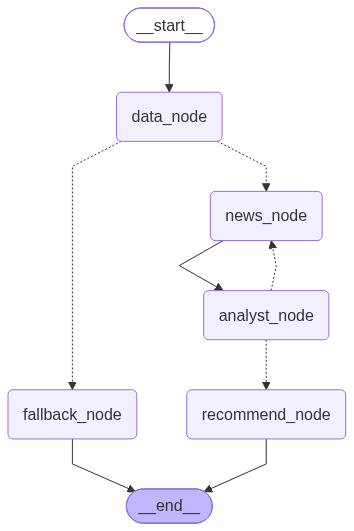

In [11]:
from IPython.display import Image, display
try:
    display(Image(agent_app.get_graph().draw_mermaid_png()))
except Exception:
    print(agent_app.get_graph().draw_mermaid())   # paste into https://mermaid.live if image fails

In [12]:
import os
from google.colab import userdata

os.environ["LLM_PROVIDER"] = "groq"
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
os.environ["LLM_MODEL"] = "openai/gpt-oss-20b"
print("Groq ready")

Groq ready


## 8. Run the agent (watch each agent finish)
NSE stocks need `.NS` (e.g. `RELIANCE.NS`, `TCS.NS`, `HDFCBANK.NS`); US stocks: `AAPL`, `MSFT`.

In [13]:
from IPython.display import Markdown, display
result = run_agent_safe("RELIANCE.NS", period="1y", verbose=True)
display(Markdown(format_report(result)))

✔ finished: data_node


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✔ finished: news_node
✔ finished: analyst_node
✔ finished: recommend_node


## 🟡 HOLD  (confidence 60%)
**Reliance Industries Limited (RELIANCE.NS)**  |  Horizon: short‑term (1‑3 months)

**Justification:** Reliance’s price is at the 52‑week low of ₹1,167.7 and sits below both the 20‑period SMA (₹1,242.77) and 50‑period SMA (₹1,279.77), confirming a bearish trend.  The RSI is 27.92 (<30) and MACD is –28.795 below its signal line –21.98, indicating oversold conditions that could trigger a short‑term rebound if support holds.  However, the recent earnings beat and analyst upgrades provide upside sentiment, and the mid‑August rally suggests potential catalysts, yet the new private‑placement debentures add leverage risk and the sustained low streak signals ongoing downside pressure.  A breakout above the 52‑week high of ₹1,584.97 would be required for a sustained upside, which is currently unlikely.

**Key risks:** New private‑placement debentures increasing leverage and dilution; Sustained 52‑week low streak indicating downside pressure

_Simulated output for educational purposes only. This is NOT financial advice._

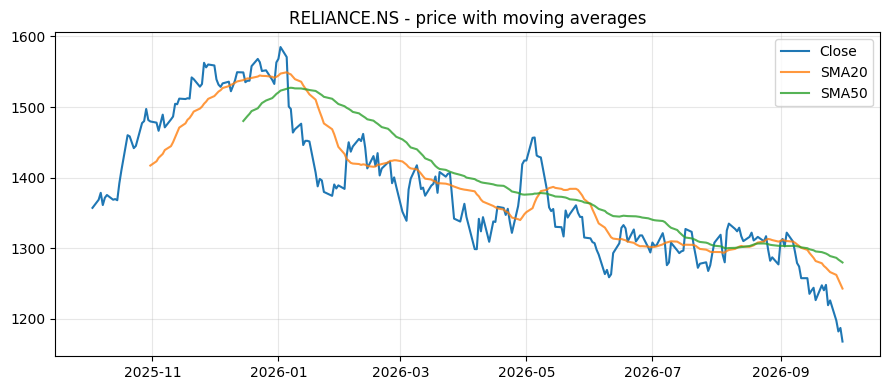

In [14]:
plot_price("RELIANCE.NS", "1y")
plt.show()

### Intermediate outputs (useful for the report / PPT)

In [15]:
print("TECHNICAL SUMMARY:\n", result["technical_summary"], "\n")
print("NEWS SUMMARY (RAG):\n", result["news_summary"], "\n")
print("ANALYSIS:\n", result["analysis"])
print("\nBullish:", result["bullish"]); print("Bearish:", result["bearish"])
print("Confidence:", result["confidence"], "| news fetch rounds:", result["retry_count"])

TECHNICAL SUMMARY:
 **RELIANCE.NS – Technical Snapshot (as of 2026‑10‑01)**  

| Metric | Value | Interpretation |
|--------|-------|----------------|
| **Last close** | ₹1,167.7 | Current price sits at the 52‑week low. |
| **Trend** | Price below SMA 20 (₹1,242.8) and SMA 50 (₹1,279.8) | Clear down‑trend; price is below both short‑ and medium‑term moving averages. |
| **Momentum** | RSI 14 = 27.9 (oversold) < 30 | Weak buying pressure; potential for a rebound if support holds. <br>MACD = –28.8, MACD‑signal = –22.0 → MACD below signal → bearish momentum. |
| **Volatility** | Annualised vol = 18.6 % | Moderately high; price swings are significant relative to the current level. |
| **52‑week range** | Low = ₹1,167.7, High = ₹1,584.97 | Current price is at the 52‑week low, indicating strong support at ₹1,167.7. The upper bound of ₹1,584.97 represents a key resistance level. |

**Summary**  
- **Trend:** Downward; price is below both SMA 20 and SMA 50.  
- **Momentum:** Oversold RSI and be

## 9. Test on more tickers + invalid ticker (tests the conditional edge to `fallback_node`)

In [16]:
import logging
logging.getLogger("yfinance").setLevel(logging.CRITICAL)

for t in ["TCS.NS", "AAPL", "NOTAREALTICKER"]:
    print("=" * 60, t)
    r = run_agent(t)
    print(r["recommendation"]["action"], "|", r["recommendation"]["justification"][:200])

============================================================ TCS.NS
HOLD | TCS.NS is trading below both its 20‑day (2154.95) and 50‑day (2275.59) moving averages, with an RSI of 36.04 and MACD of –61.94 below its signal line – all bearish signals.  However, the stock saw a 7
============================================================ AAPL
HOLD | Apple’s last close of $333.69 sits just above its 20‑day SMA of $331.89 and 50‑day SMA of $322.36, confirming a short‑term uptrend, but the MACD of 3.821 is below its signal line of 4.839, indicating 
============================================================ NOTAREALTICKER
HOLD | Could not complete analysis: Not enough price data for 'NOTAREALTICKER'. Check the ticker (NSE stocks need .NS).


## 10. Gradio app (same code as `app.py` for deployment)

In [17]:
import gradio as gr

def analyze(ticker, period):
    s = run_agent(ticker, period)
    if s.get("error"):
        return None, format_report(s), "", ""
    return plot_price(s["ticker"], period), format_report(s), s["news_summary"], s["analysis"]

with gr.Blocks(title="AI Stock Market Assistant") as demo:
    gr.Markdown("# AI Stock Market Assistant\nMulti-agent (LangGraph) · RAG news · simulated recommendation")
    with gr.Row():
        t = gr.Textbox(label="Ticker", value="RELIANCE.NS")
        p = gr.Dropdown(["6mo", "1y", "2y"], value="1y", label="Period")
        b = gr.Button("Analyze", variant="primary")
    plot = gr.Plot(); rec = gr.Markdown()
    with gr.Tab("News summary (RAG)"): news = gr.Markdown()
    with gr.Tab("Analysis"): ana = gr.Markdown()
    b.click(analyze, [t, p], [plot, rec, news, ana])

demo.launch()   # add share=True for a public link

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9710cdcbec2cae470e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Limitations and future scope
- News from RSS is headline-level, so it can lag and miss detail; premium news APIs would improve RAG quality.
- LLM reasoning can hallucinate; mitigated by grounding on retrieved context, computing indicators in Python and a confidence-based retry loop.
- Recommendations are simulated; no backtesting, no fundamentals (P/E, balance sheet) and no portfolio context yet.
- Future: add a fundamentals agent, backtesting agent, risk/portfolio agent, and a vector DB such as Chroma for persistent news memory.